# Data Exploration — Jobs, Skills & Personality Datasets

This notebook explores four files:

| # | File | What it is |
|---|------|-----------|
| 1 | `Analytics Jobs.csv` | ~15.8k job postings (title, skills, location, experience, salary band) |
| 2 | `DataScience Jobs.csv` | ~1.6k company × job-title salary records (Glassdoor-style) |
| 3 | `JDS Skill Traits.xlsx` | 139 people: 5 skill ratings (1–5) + high/low salary-hike label |
| 4 | `SDS Personality Traits.xlsx` | 161 people: Big-Five personality scores + high/low success label |

Sections: **0 Setup → 1 Overview → 2 Analytics Jobs → 3 DataScience Jobs → 4 JDS Skills → 5 SDS Personality → 6 Cross-dataset check → 7 Save cleaned data → 8 Key insights**

The next step, statistical tests and models, is in `data_analysis.ipynb`.

## 0. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 60)

# Chart style: one consistent palette, recessive grid, no top/right spines
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
    'legend.frameon': False, 'figure.dpi': 110,
})

def hbar(series, title, xlabel, color=BLUE, fmt='{:,.0f}', ax=None):
    """Horizontal bar chart, largest on top, value label at the end of each bar."""
    s = series.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(s.values):
        ax.text(v, i, ' ' + fmt.format(v), va='center', fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_xlabel(xlabel)
    return ax

## 1. Load & overview

In [2]:
analytics = pd.read_csv('Analytics Jobs.csv')
ds        = pd.read_csv('DataScience Jobs.csv')
jds       = pd.read_excel('JDS Skill Traits.xlsx')
sds       = pd.read_excel('SDS Personality Traits.xlsx')

datasets = {'Analytics Jobs': analytics, 'DataScience Jobs': ds,
            'JDS Skill Traits': jds, 'SDS Personality Traits': sds}

overview = pd.DataFrame({
    name: {'rows': df.shape[0], 'columns': df.shape[1],
           'missing cells': int(df.isna().sum().sum()),
           'duplicate rows': int(df.duplicated().sum())}
    for name, df in datasets.items()}).T
overview

,rows,columns,missing cells,duplicate rows
Analytics Jobs,15841,8,15520,0
DataScience Jobs,1602,8,0,0
JDS Skill Traits,139,7,0,0
SDS Personality Traits,161,7,0,0


In [3]:
# Missing values per column (only columns that have any)
for name, df in datasets.items():
    nulls = df.isna().sum()
    nulls = nulls[nulls > 0]
    print(f'{name}:', 'no missing values' if nulls.empty else '')
    if not nulls.empty:
        print((nulls / len(df) * 100).round(1).astype(str).add('%').to_string(), '\n')

Analytics Jobs: 
job_description    22.1%
job_type           75.8%
key_skills          0.0% 

DataScience Jobs: no missing values
JDS Skill Traits: no missing values
SDS Personality Traits: no missing values


In [4]:
# Column-name problems: leading/trailing or embedded spaces
for name, df in datasets.items():
    bad = [c for c in df.columns if c != c.strip() or ' ' in c]
    if bad:
        print(name, '->', bad)

# Fix them so later code is clean
sds.columns = [re.sub(r'\s+', '', c) for c in sds.columns]
sds = sds.rename(columns={'success_classification_high_low': 'success_high'})
jds = jds.rename(columns={'salary_hike_high_or_low': 'hike_high', 'maths-stats_skills': 'maths_stats_skills'})
print('SDS columns:', list(sds.columns))
print('JDS columns:', list(jds.columns))

SDS Personality Traits -> [' extraversion', 'success_ classification_ high_low']
SDS columns: ['id', 'neuroticism', 'extraversion', 'openness_to_experience', 'agreeableness', 'conscientiousness', 'success_high']
JDS columns: ['id', 'big_data_skills', 'maths_stats_skills', 'coding_skills', 'ai_and_ml_skills', 'dashboard_and_storytelling_skills', 'hike_high']


## 2. Analytics Jobs.csv

### 2.1 Raw sample and column types

In [5]:
analytics.head()

,s_no,experience,job_description,job_desig,job_type,key_skills,location,salary
0,1,6-10 yrs,Must be knowledgeable and experienced in relational data...,Oracle EBS Technical Consultant,NaN,"Oracle SQL, PLSQL, PL, Oracle Forms, Oracle Reports, Ora...","Bengaluru, Chennai",6to10
1,2,8-12 yrs,- Experience in building scalable and highly available d...,Staff Software Engineer - Object Oriented Analysis & Design,NaN,"Javascript, HTML, JQuery, Web Development, Play Framewor...",Bengaluru,10to15
2,3,3-8 yrs,NaN,Servicenow Developer,NaN,"SNOW, Servicenow, Servicenow Developer","Hyderabad, Pune",0to3
3,4,3-6 yrs,Our software engineers at Fiserv bring an open and ...,"Software Development Engineering, Analyst",NaN,"QTP, Flex, LAN, Application support, Performance testing...",Pune,6to10
4,5,5-10 yrs,- More than 5 years experience in Hypermesh for Finite E...,NVH Engineer - Nastran/ Ls-dyna,NaN,"HyperMesh, LS - DYNA, NASTRAN, Abaqus, Fatigue, Durabili...","Mumbai, Bengaluru, Hyderabad, Pune, Delhi",10to15


In [6]:
analytics.describe(include='all').T[['count', 'unique', 'top', 'freq']]

,count,unique,top,freq
s_no,15841.0,NaN,NaN,NaN
experience,15841,128,5-10 yrs,1010
job_description,12333,7859,Accenture Technology powers our clients businesses with ...,117
job_desig,15841,10097,Business Analyst,108
job_type,3830,5,Analytics,2971
key_skills,15840,11155,"part time, freelancing, data entry, present job, work fr...",66
location,15841,1355,Bengaluru,3333
salary,15841,6,10to15,3608


### 2.2 Cleaning
- Remove **exact duplicate postings** (identical except for `s_no`)
- `experience` text (`'5-10 yrs'`) → numeric `exp_min`, `exp_max`
- `job_type` has 5 spellings of *Analytics* → normalise
- `salary` band → ordered category + midpoint (lakhs)
- Check how much of the text columns are truncated (`...`)
- Normalise `location` (sub-areas, `+n` suffixes, spelling variants)
- Flag suspicious rows (junk postings, experience/salary conflicts) instead of silently deleting them

In [7]:
n0 = len(analytics)
a = analytics.drop_duplicates(subset=[c for c in analytics.columns if c != 's_no']).copy()
print(f'Exact duplicate postings removed: {n0 - len(a):,}  ({n0:,} -> {len(a):,} rows)')

exp = a['experience'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float)
a['exp_min'], a['exp_max'] = exp[0], exp[1]

print('job_type before:', a['job_type'].value_counts(dropna=False).to_dict())
a['job_type'] = a['job_type'].str.lower().str.replace(r'^analytic$', 'analytics', regex=True)
print('job_type after: ', a['job_type'].value_counts(dropna=False).to_dict())

band_order = ['0to3', '3to6', '6to10', '10to15', '15to25', '25to50']
band_mid   = {'0to3': 1.5, '3to6': 4.5, '6to10': 8, '10to15': 12.5, '15to25': 20, '25to50': 37.5}
a['salary'] = pd.Categorical(a['salary'], categories=band_order, ordered=True)
a['salary_mid_L'] = a['salary'].map(band_mid).astype(float)

print('\nTruncated text (ends with "..."):')
for c in ['job_description', 'key_skills']:
    print(f'  {c:16s} {a[c].str.endswith("...").mean():.0%} of rows   | missing: {a[c].isna().mean():.1%}')
print('\nexp_min / exp_max summary:')
a[['exp_min', 'exp_max']].describe().round(1)

Exact duplicate postings removed: 1,001  (15,841 -> 14,840 rows)


job_type before: {nan: 11567, 'Analytics': 2459, 'analytics': 712, 'ANALYTICS': 59, 'analytic': 28, 'Analytic': 15}
job_type after:  {nan: 11567, 'analytics': 3273}

Truncated text (ends with "..."):
  job_description  77% of rows   | missing: 22.7%
  key_skills       87% of rows   | missing: 0.0%

exp_min / exp_max summary:


,exp_min,exp_max
count,14840.0,14840.0
mean,4.2,7.9
std,3.3,4.2
min,0.0,0.0
25%,2.0,5.0
50%,3.0,7.0
75%,6.0,10.0
max,23.0,30.0


In [8]:
# --- Location normalisation -------------------------------------------------
# Raw values look like 'Bengaluru(Whitefield)', 'Bengaluru(HSR Layout+1)', 'Bengaluru / Bangalore', 'Gurugram'
CITY_MAP = {'Bangalore': 'Bengaluru', 'Bengaluru / Bangalore': 'Bengaluru', 'Bangalore/Bengaluru': 'Bengaluru',
            'Gurugram': 'Gurgaon', 'Delhi': 'Delhi NCR', 'New Delhi': 'Delhi NCR',
            'Navi Mumbai': 'Mumbai', 'Mumbai Suburbs': 'Mumbai', 'Thane': 'Mumbai',
            'Greater Noida': 'Noida', 'Secunderabad': 'Hyderabad', 'Calcutta': 'Kolkata', 'Madras': 'Chennai'}

def clean_cities(loc):
    out = []
    for part in str(loc).split(','):
        c = re.sub(r'\(.*', '', part)          # drop '(sub-area...' incl. unclosed brackets
        c = re.sub(r'\+\d+', '', c).strip()      # drop '+1' style suffixes
        c = CITY_MAP.get(c, c)
        if c and c not in out:
            out.append(c)
    return out

a['cities'] = a['location'].map(clean_cities)
a['primary_city'] = a['cities'].str[0]
a['n_cities'] = a['cities'].str.len()
raw_parts = a['location'].str.split(',').explode().str.strip()
print(f"Distinct location tokens: raw {raw_parts.nunique():,} -> cleaned {a['cities'].explode().nunique():,}")
print('Postings listing several cities:', f"{(a['n_cities'] > 1).mean():.0%}")

# --- Flags for suspicious rows (kept, but marked) -----------------------------
a['is_fresher'] = a['exp_max'] == 0
a['junk_posting'] = a['job_desig'].str.contains(r'data entry|part time|home base|freelanc|work from home|walk-?in', case=False)
a['exp_band_conflict'] = (a['exp_min'] >= 10) & (a['salary'] == '0to3')   # 10+ yrs experience but < 3 L pay
print('\nFlags:', a[['is_fresher', 'junk_posting', 'exp_band_conflict']].sum().to_dict())
a.loc[a['exp_band_conflict'], ['job_desig', 'experience', 'salary']].head()

Distinct location tokens: raw 927 -> cleaned 467
Postings listing several cities: 13%

Flags: {'is_fresher': 113, 'junk_posting': 295, 'exp_band_conflict': 10}


,job_desig,experience,salary
2049,Sales Manager - Abu Dhabi ( for both Offshore and Logist...,10-15 yrs,0to3
2332,Business Analyst ( Hospitality ),10-20 yrs,0to3
3865,Senior Manager -costing,10-15 yrs,0to3
5678,Urgent Opening for Project Manager_it Company (product B...,10-12 yrs,0to3
6737,Solution Architect - Java/j2ee Background ONLY,12-19 yrs,0to3


### 2.3 Salary band distribution

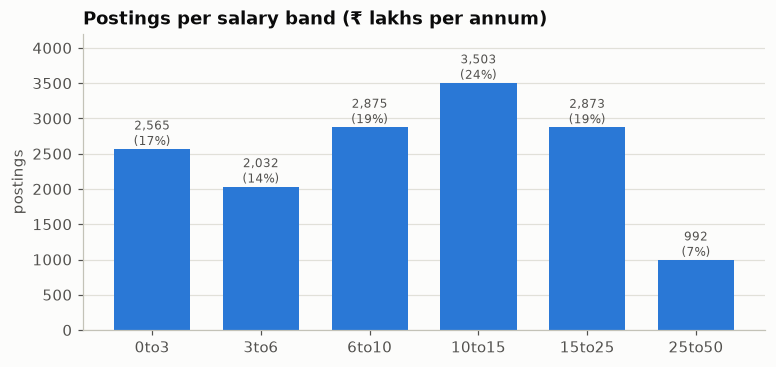

In [9]:
counts = a['salary'].value_counts().reindex(band_order)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.7)
ax.grid(axis='x', visible=False)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v/len(a):.0%})', ha='center', va='bottom', fontsize=8, color=MUTED)
ax.set_title('Postings per salary band (₹ lakhs per annum)'); ax.set_ylabel('postings'); ax.set_ylim(0, counts.max()*1.2)
plt.show()

### 2.4 Experience vs salary

        exp_min  exp_max
salary                  
0to3        1.0      4.0
3to6        2.0      5.0
6to10       3.0      6.0
10to15      5.0      8.0
15to25      6.0     10.0
25to50     10.0     14.0


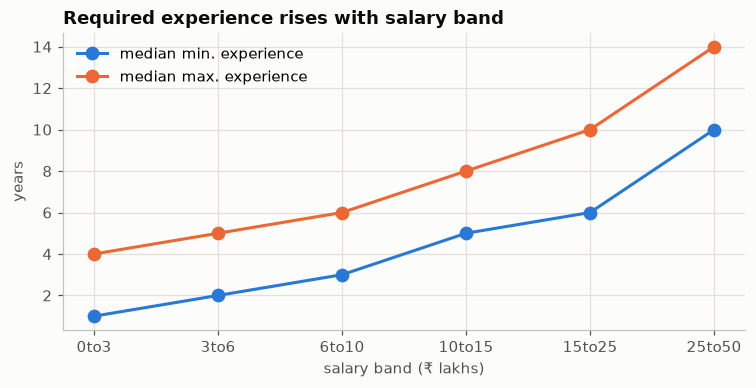

Correlation exp_min vs salary midpoint: 0.65


In [10]:
exp_by_band = a.groupby('salary', observed=True)[['exp_min', 'exp_max']].median()
print(exp_by_band)

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(band_order))
ax.plot(x, exp_by_band['exp_min'], marker='o', color=BLUE, lw=2, ms=8, label='median min. experience')
ax.plot(x, exp_by_band['exp_max'], marker='o', color=ORANGE, lw=2, ms=8, label='median max. experience')
ax.set_xticks(x, band_order); ax.set_xlabel('salary band (₹ lakhs)'); ax.set_ylabel('years')
ax.set_title('Required experience rises with salary band'); ax.legend(loc='upper left')
plt.show()

print('Correlation exp_min vs salary midpoint:', round(a['exp_min'].corr(a['salary_mid_L']), 2))

### 2.5 Locations
Uses the normalised `cities` list from 2.2, so each posting counts once per city it mentions.

unique raw location strings: 1355 | unique cities after cleaning: 467


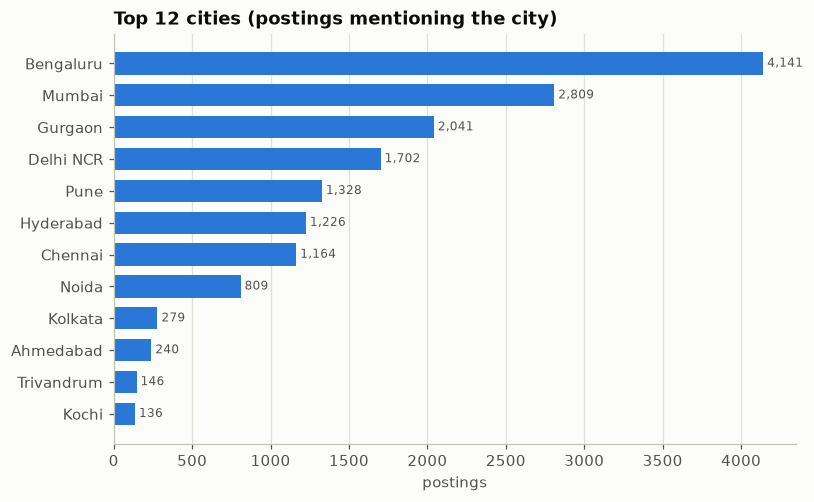

In [11]:
city = a['cities'].explode()
print('unique raw location strings:', a['location'].nunique(), '| unique cities after cleaning:', city.nunique())
hbar(city.value_counts().head(12), 'Top 12 cities (postings mentioning the city)', 'postings')
plt.show()

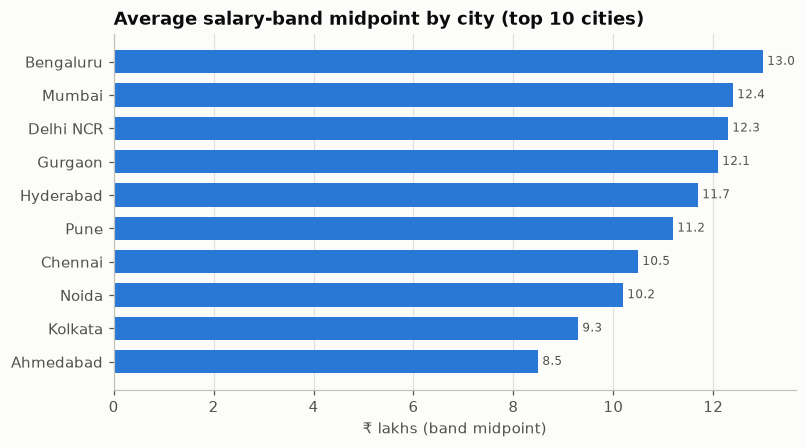

In [12]:
# Salary by city: average band midpoint for top cities
a_city = a[['salary_mid_L', 'cities']].explode('cities').rename(columns={'cities': 'city'})
top_cities = city.value_counts().head(10).index
city_sal = a_city[a_city['city'].isin(top_cities)].groupby('city')['salary_mid_L'].mean().round(1)
hbar(city_sal, 'Average salary-band midpoint by city (top 10 cities)', '₹ lakhs (band midpoint)', fmt='{:.1f}')
plt.show()

### 2.6 Key skills
The skill lists are cut off (`...`), so counts reflect only the first few skills listed per posting.

unique skills: 8532


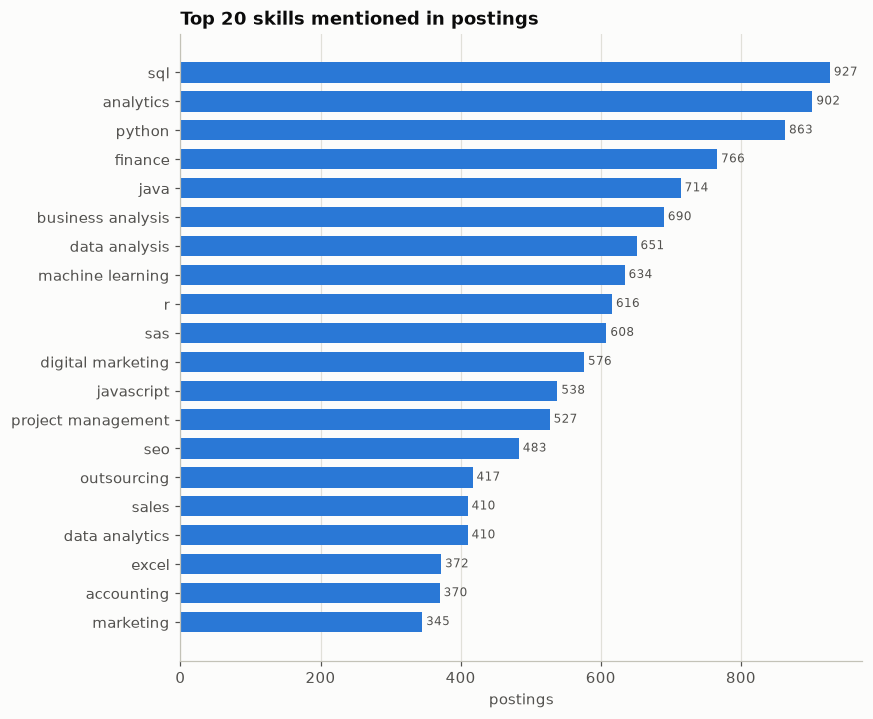

In [13]:
skills = (a['key_skills'].dropna().str.replace('...', '', regex=False)
            .str.split(',').explode().str.strip().str.lower())
skills = skills[skills != '']
print('unique skills:', skills.nunique())
hbar(skills.value_counts().head(20), 'Top 20 skills mentioned in postings', 'postings')
plt.show()

overall average band midpoint: 11.8 L


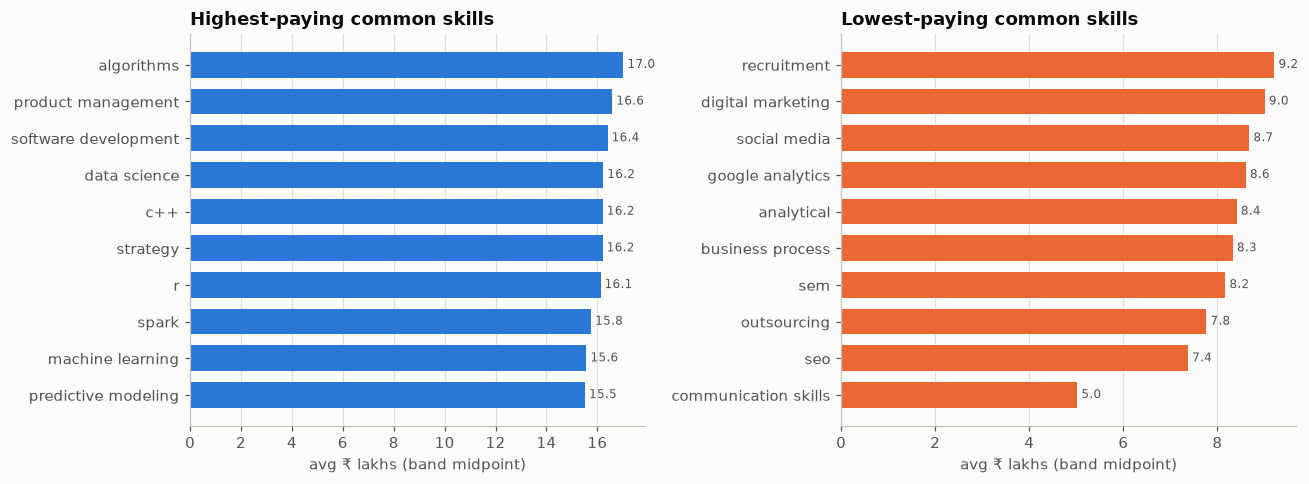

In [14]:
# Which skills are associated with higher pay? (skills with >=150 postings)
sk = (a[['key_skills', 'salary_mid_L']].dropna()
        .assign(skill=lambda d: d['key_skills'].str.replace('...', '', regex=False).str.lower().str.split(','))
        .explode('skill'))
sk['skill'] = sk['skill'].str.strip()
sk_stats = sk[sk['skill'] != ''].groupby('skill')['salary_mid_L'].agg(['count', 'mean'])
sk_stats = sk_stats[sk_stats['count'] >= 150].sort_values('mean')
print('overall average band midpoint:', round(a['salary_mid_L'].mean(), 1), 'L')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
hbar(sk_stats['mean'].tail(10), 'Highest-paying common skills', 'avg ₹ lakhs (band midpoint)', color=BLUE, fmt='{:.1f}', ax=axes[0])
hbar(sk_stats['mean'].head(10), 'Lowest-paying common skills', 'avg ₹ lakhs (band midpoint)', color=ORANGE, fmt='{:.1f}', ax=axes[1])
plt.tight_layout(); plt.show()

### 2.7 Job titles — what roles are in the file?

In [15]:
print('unique job titles:', a['job_desig'].nunique())
print(a['job_desig'].value_counts().head(15))

role_patterns = {
    'Data Scientist / ML': r'data scien|machine learning|\bml\b|deep learning|\bai\b',
    'Data / Business Analyst': r'data analy|business analy|\banalyst\b',
    'Data Engineer / Big Data': r'data engineer|big data|hadoop|spark',
    'Software / Developer': r'developer|software|engineer|programmer|java|\.net',
    'Marketing / SEO / Sales': r'marketing|seo|sales|business development',
    'Finance / Accounts': r'financ|account|audit|tax',
}
title = a['job_desig'].str.lower()
a['role_group'] = 'Other'
for g, pat in reversed(list(role_patterns.items())):   # first pattern wins
    a.loc[title.str.contains(pat, regex=True), 'role_group'] = g

role_summary = a.groupby('role_group').agg(postings=('s_no', 'size'),
                                            avg_salary_L=('salary_mid_L', 'mean'),
                                            median_exp_min=('exp_min', 'median')).round(1)
role_summary.sort_values('postings', ascending=False)

unique job titles: 10097
job_desig
Business Analyst                                                        102
Data Scientist                                                           62
Data Analyst                                                             48
Product Manager                                                          44
Digital Marketing Manager                                                43
Home Base Job/ Data Entry/online Work/part Time Work/freelancer work     42
Digital Marketing Executive                                              35
Analyst                                                                  35
SEO Executive                                                            27
Associate                                                                24
Microsoft Advanced Analytics                                             23
SEO Analyst                                                              23
Software Engineer                                    

,postings,avg_salary_L,median_exp_min
role_group,,,
Other,6366,12.2,4.0
Data / Business Analyst,3196,9.8,3.0
Software / Developer,2140,11.8,4.0
Marketing / SEO / Sales,1422,10.3,3.0
Finance / Accounts,741,13.3,4.0
Data Scientist / ML,624,16.4,4.0
Data Engineer / Big Data,351,14.7,5.0


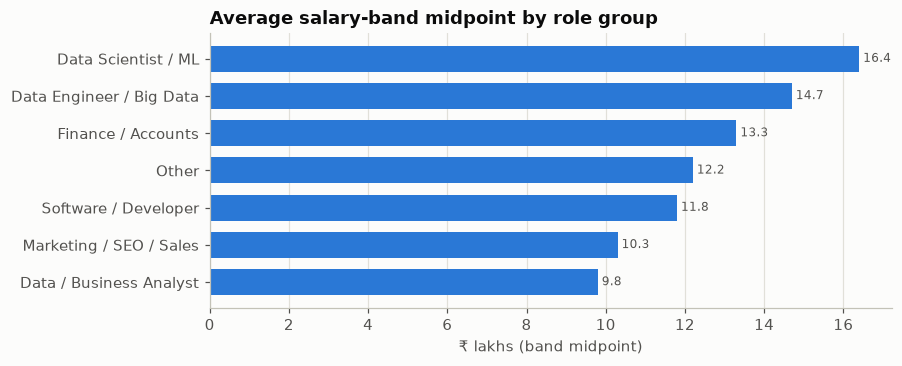

In [16]:
hbar(role_summary['avg_salary_L'], 'Average salary-band midpoint by role group', '₹ lakhs (band midpoint)', fmt='{:.1f}')
plt.show()

## 3. DataScience Jobs.csv

In [17]:
d = ds.copy()
for c in ['avg_salary', 'min_salary', 'max_salary']:
    d[c + '_L'] = pd.to_numeric(d[c].str.rstrip('L'), errors='coerce')
print('unparseable salaries:', int(d[['avg_salary_L', 'min_salary_L', 'max_salary_L']].isna().sum().sum()))
print('rows where min <= avg <= max:', f"{((d.min_salary_L <= d.avg_salary_L) & (d.avg_salary_L <= d.max_salary_L)).mean():.1%}")
d[['min_experience', 'avg_salary_L', 'min_salary_L', 'max_salary_L', 'num_of_jobs']].describe().round(1)

unparseable salaries: 0
rows where min <= avg <= max: 100.0%


,min_experience,avg_salary_L,min_salary_L,max_salary_L,num_of_jobs
count,1602.0,1602.0,1602.0,1602.0,1602.0
mean,2.8,13.2,8.6,19.1,58.1
std,2.4,7.8,5.8,11.2,169.0
min,0.0,1.4,0.2,2.0,3.0
25%,1.0,7.6,4.4,12.0,9.2
50%,2.0,11.9,7.0,18.0,22.0
75%,4.0,17.2,11.5,24.0,47.0
max,21.0,82.0,55.0,102.0,4200.0


In [18]:
print('unique companies:', d['company_name'].nunique(), '| unique titles:', d['job_title'].nunique())
d['job_title'].value_counts()

unique companies: 642 | unique titles: 10


job_title
Data Scientist               188
Business Analyst             188
Data Engineer                188
Data Analyst                 187
Senior Business Analyst      187
Senior Data Analyst          187
Senior Data Scientist        185
Senior Data Engineer         183
Machine Learning Engineer     59
Data Architect                50
Name: count, dtype: int64

### 3.1 Salary by job title

,records,median_avg_L,median_min_exp,total_jobs
job_title,,,,
Data Architect,50,24.25,10.0,528
Senior Data Scientist,185,21.20,4.0,2129
Senior Data Engineer,183,17.60,4.0,3411
Senior Business Analyst,187,13.00,4.0,14115
Data Scientist,188,12.80,2.0,9051
Data Engineer,188,10.85,1.0,8044
Machine Learning Engineer,59,9.10,1.0,964
Senior Data Analyst,187,8.60,3.0,3825
Business Analyst,188,8.30,2.0,32843


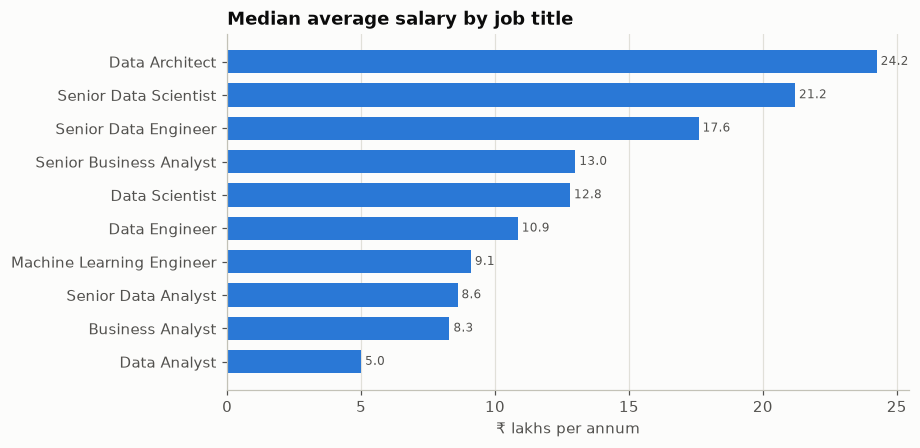

In [19]:
title_stats = (d.groupby('job_title')
                 .agg(records=('avg_salary_L', 'size'), median_avg_L=('avg_salary_L', 'median'),
                      median_min_exp=('min_experience', 'median'), total_jobs=('num_of_jobs', 'sum'))
                 .sort_values('median_avg_L', ascending=False))
display(title_stats)
hbar(title_stats['median_avg_L'], 'Median average salary by job title', '₹ lakhs per annum', fmt='{:.1f}')
plt.show()

,junior_L,senior_L,uplift_%
Data Scientist,12.80,21.2,66.0
Data Analyst,5.00,8.6,72.0
Data Engineer,10.85,17.6,62.0
Business Analyst,8.30,13.0,57.0


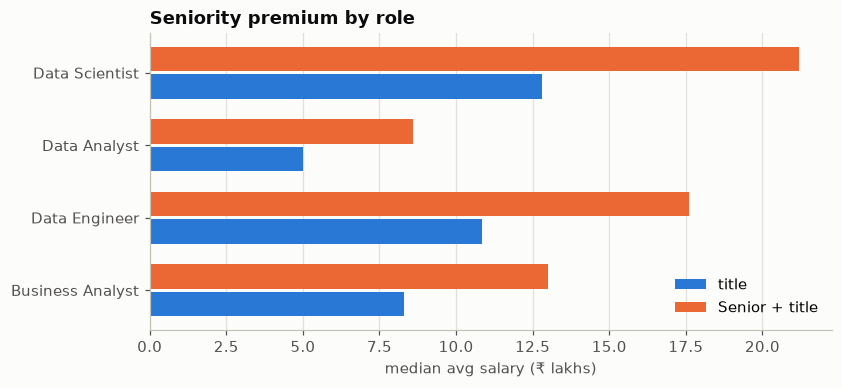

In [20]:
# Senior premium: Senior X vs X
pairs = ['Data Scientist', 'Data Analyst', 'Data Engineer', 'Business Analyst']
prem = pd.DataFrame({'junior_L': [title_stats.loc[t, 'median_avg_L'] for t in pairs],
                     'senior_L': [title_stats.loc['Senior ' + t, 'median_avg_L'] for t in pairs]}, index=pairs)
prem['uplift_%'] = ((prem['senior_L'] / prem['junior_L'] - 1) * 100).round(0)
display(prem)

fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(pairs)); h = 0.38
ax.barh(y + h/2, prem['junior_L'], h - 0.04, color=BLUE, label='title')
ax.barh(y - h/2, prem['senior_L'], h - 0.04, color=ORANGE, label='Senior + title')
ax.set_yticks(y, pairs); ax.grid(axis='y', visible=False); ax.invert_yaxis()
ax.set_xlabel('median avg salary (₹ lakhs)'); ax.set_title('Seniority premium by role'); ax.legend(loc='lower right')
plt.show()

### 3.2 Experience vs salary

min_experience     0      1      2      3      4      5     6     7     8     9     10
median            6.4    7.8   11.4   12.8   15.2   16.4  18.2  22.0  22.2  22.4  25.6
count           170.0  358.0  356.0  233.0  191.0  125.0  55.0  48.0  27.0  10.0  10.0


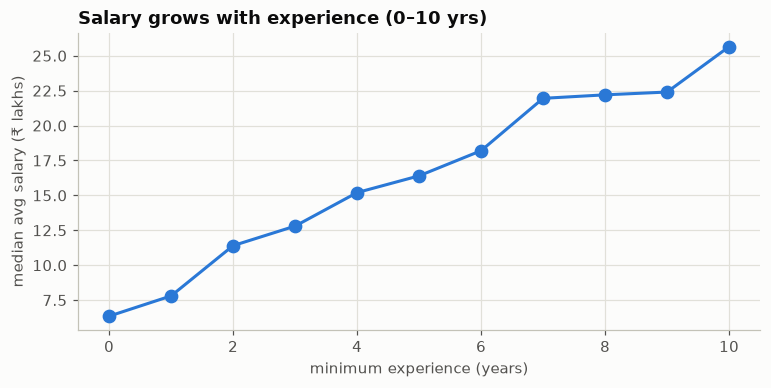

Correlation min_experience vs avg_salary: 0.59


In [21]:
exp_sal = d[d['min_experience'] <= 10].groupby('min_experience')['avg_salary_L'].agg(['median', 'count'])
print(exp_sal.T.round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(exp_sal.index, exp_sal['median'], marker='o', color=BLUE, lw=2, ms=8)
ax.set_xlabel('minimum experience (years)'); ax.set_ylabel('median avg salary (₹ lakhs)')
ax.set_title('Salary grows with experience (0–10 yrs)')
plt.show()
print('Correlation min_experience vs avg_salary:', round(d['min_experience'].corr(d['avg_salary_L']), 2))

### 3.3 Companies — who hires most, who pays most

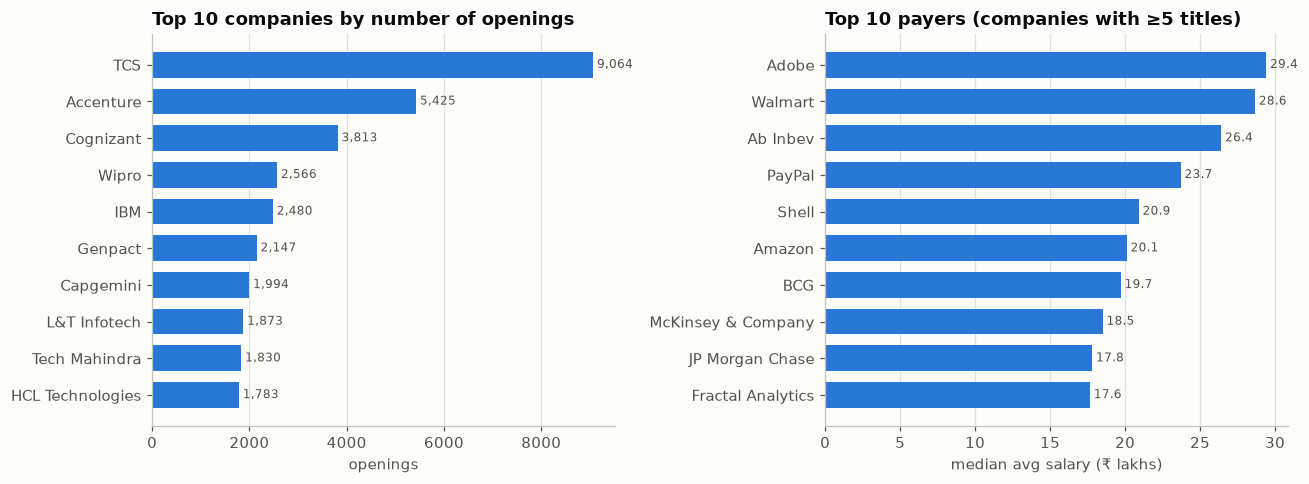

Median pay at the 8 biggest hirers: 9.8 L | everyone else: 12.0 L


In [22]:
comp = d.groupby('company_name').agg(total_jobs=('num_of_jobs', 'sum'), median_avg_L=('avg_salary_L', 'median'),
                                     titles=('job_title', 'nunique'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
hbar(comp['total_jobs'].nlargest(10), 'Top 10 companies by number of openings', 'openings', ax=axes[0])
hbar(comp[comp['titles'] >= 5]['median_avg_L'].nlargest(10), 'Top 10 payers (companies with ≥5 titles)',
     'median avg salary (₹ lakhs)', fmt='{:.1f}', ax=axes[1])
plt.tight_layout(); plt.show()

top8 = comp['total_jobs'].nlargest(8).index
print('Median pay at the 8 biggest hirers:', round(d[d.company_name.isin(top8)]['avg_salary_L'].median(), 1), 'L',
      '| everyone else:', round(d[~d.company_name.isin(top8)]['avg_salary_L'].median(), 1), 'L')

In [23]:
# Salary spread (max/min) — how wide is the pay range within one company+title?
d['spread_x'] = d['max_salary_L'] / d['min_salary_L']
print(d['spread_x'].describe().round(1))
print('\nOutliers — highest average salaries:')
d.nlargest(5, 'avg_salary_L')[['company_name', 'job_title', 'min_experience', 'avg_salary', 'num_of_jobs']]

count    1602.0
mean        2.6
std         2.3
min         1.0
25%         1.8
50%         2.2
75%         3.0
max        70.0
Name: spread_x, dtype: float64

Outliers — highest average salaries:


,company_name,job_title,min_experience,avg_salary,num_of_jobs
897,Flipkart,Senior Data Scientist,5,82.0L,5
1442,Emirates Airlines,Senior Data Engineer,6,68.3L,5
1462,Uber,Senior Data Engineer,7,66.3L,5
770,Microsoft Corporation,Senior Data Scientist,4,56.4L,22
1585,Fidelity International,Data Architect,8,50.6L,4


IQR outliers (overall): 39 | within own job title: 53
Outliers by title: {'Senior Data Scientist': 19, 'Data Architect': 9, 'Senior Data Engineer': 8, 'Data Scientist': 2, 'Data Engineer': 1}


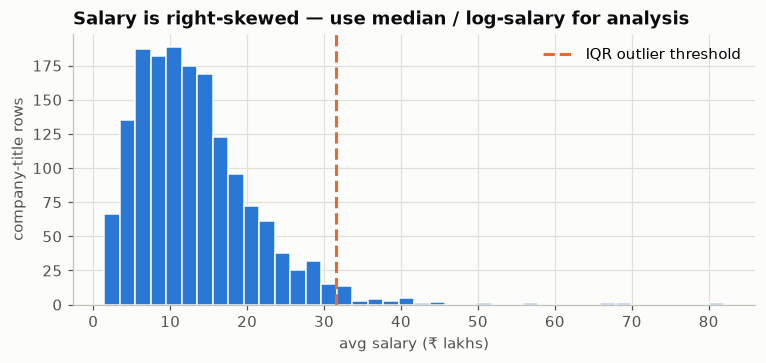

Skewness: raw 1.74 | log -0.45


In [24]:
# Outlier treatment decision: IQR flag on avg salary, overall and within job title
q1, q3 = d['avg_salary_L'].quantile([.25, .75])
d['salary_outlier'] = d['avg_salary_L'] > q3 + 1.5 * (q3 - q1)
g = d.groupby('job_title')['avg_salary_L']
d['salary_outlier_in_title'] = d['avg_salary_L'] > g.transform(lambda s: s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25)))
print('IQR outliers (overall):', int(d['salary_outlier'].sum()), '| within own job title:', int(d['salary_outlier_in_title'].sum()))
print('Outliers by title:', d[d['salary_outlier']]['job_title'].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d['avg_salary_L'], bins=40, color=BLUE, edgecolor='#fcfcfb')
ax.axvline(q3 + 1.5 * (q3 - q1), color=ORANGE, lw=2, ls='--', label='IQR outlier threshold')
ax.set_xlabel('avg salary (₹ lakhs)'); ax.set_ylabel('company-title rows'); ax.legend()
ax.set_title('Salary is right-skewed — use median / log-salary for analysis')
plt.show()
print('Skewness: raw', round(d['avg_salary_L'].skew(), 2), '| log', round(np.log(d['avg_salary_L']).skew(), 2))
# Decision: outliers are mostly senior / architect roles at product firms -> genuine, kept, analysed on log scale.

## 4. JDS Skill Traits — what skills go with a high salary hike?

In [25]:
skill_cols = ['big_data_skills', 'maths_stats_skills', 'coding_skills', 'ai_and_ml_skills', 'dashboard_and_storytelling_skills']
print('class balance:', jds['hike_high'].value_counts().to_dict())
jds[skill_cols].describe().round(2)

class balance: {1: 73, 0: 66}


,big_data_skills,maths_stats_skills,coding_skills,ai_and_ml_skills,dashboard_and_storytelling_skills
count,139.00,139.00,139.00,139.00,139.00
mean,3.85,4.29,4.27,4.57,4.36
std,0.85,0.84,0.89,0.67,0.93
min,2.30,2.20,2.20,2.20,2.30
25%,3.10,3.80,3.35,4.40,3.75
50%,3.80,4.60,4.60,4.90,5.00
75%,4.60,5.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00


In [26]:
# Data-quality checks: value range, duplicate IDs, outliers
print('values outside 1–5:', int(((jds[skill_cols] < 1) | (jds[skill_cols] > 5)).sum().sum()))
dup = jds[jds['id'].duplicated(keep=False)].sort_values('id')
print(f"duplicate ids: {jds['id'].duplicated().sum()} — rows differ in every score, so they are ID collisions, not repeated records")
display(dup)
q1, q3 = jds[skill_cols].quantile(.25), jds[skill_cols].quantile(.75)
print('IQR outliers per skill:', ((jds[skill_cols] < q1 - 1.5*(q3-q1)) | (jds[skill_cols] > q3 + 1.5*(q3-q1))).sum().to_dict())
print('ai_and_ml is ceiling-heavy: share of 5.0 ratings =', f"{(jds['ai_and_ml_skills'] == 5).mean():.0%}",
      '— its "outliers" are just the few low scorers, so they are kept.')
jds['row_key'] = 'JDS-' + (jds.index + 1).astype(str)   # unique key replacing the non-unique id

values outside 1–5: 0
duplicate ids: 2 — rows differ in every score, so they are ID collisions, not repeated records


,id,big_data_skills,maths_stats_skills,coding_skills,ai_and_ml_skills,dashboard_and_storytelling_skills,hike_high
101,2223,3.3,3.8,5.0,3.4,2.5,0
58,2223,2.4,3.4,3.1,4.3,2.5,0
29,3291,4.8,4.5,5.0,4.8,5.0,1
3,3291,4.4,3.0,3.3,4.6,2.3,0


IQR outliers per skill: {'big_data_skills': 0, 'maths_stats_skills': 0, 'coding_skills': 0, 'ai_and_ml_skills': 18, 'dashboard_and_storytelling_skills': 0}
ai_and_ml is ceiling-heavy: share of 5.0 ratings = 49% — its "outliers" are just the few low scorers, so they are kept.


,low hike (0),high hike (1),difference,corr_with_target
dashboard_and_storytelling_skills,3.81,4.85,1.03,0.55
maths_stats_skills,3.83,4.71,0.88,0.52
coding_skills,3.85,4.64,0.79,0.44
ai_and_ml_skills,4.28,4.82,0.54,0.40
big_data_skills,3.75,3.94,0.19,0.11


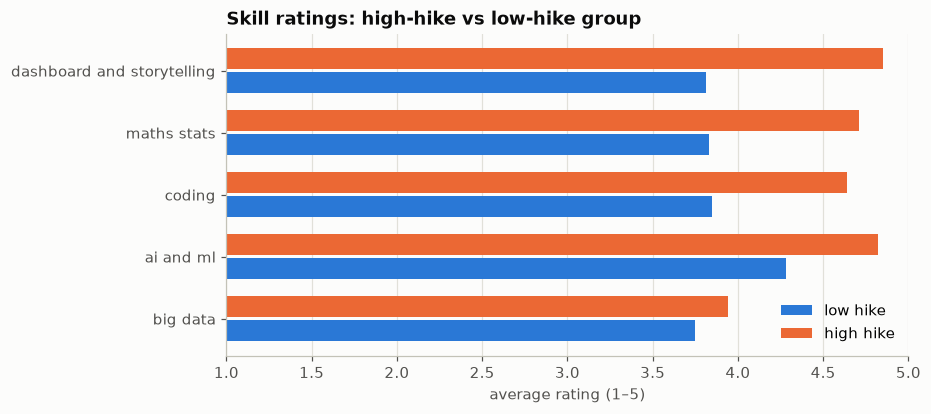

In [27]:
grp = jds.groupby('hike_high')[skill_cols].mean().T
grp.columns = ['low hike (0)', 'high hike (1)']
grp['difference'] = grp['high hike (1)'] - grp['low hike (0)']
grp['corr_with_target'] = [jds[c].corr(jds['hike_high']) for c in skill_cols]
grp = grp.sort_values('corr_with_target', ascending=False).round(2)
display(grp)

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(grp)); h = 0.38
ax.barh(y + h/2, grp['low hike (0)'], h - 0.04, color=BLUE, label='low hike')
ax.barh(y - h/2, grp['high hike (1)'], h - 0.04, color=ORANGE, label='high hike')
ax.set_yticks(y, [c.replace('_skills', '').replace('_', ' ') for c in grp.index]); ax.invert_yaxis()
ax.grid(axis='y', visible=False); ax.set_xlim(1, 5); ax.set_xlabel('average rating (1–5)')
ax.set_title('Skill ratings: high-hike vs low-hike group'); ax.legend(loc='lower right')
plt.show()

In [28]:
# How well does a simple rule separate the classes? Sum of all five skills vs a threshold.
jds['skill_total'] = jds[skill_cols].sum(axis=1)
best = max(((t, ((jds['skill_total'] >= t) == jds['hike_high']).mean()) for t in np.arange(10, 25, 0.1)), key=lambda x: x[1])
print(f'Rule "total skill score >= {best[0]:.1f} -> high hike" is right for {best[1]:.0%} of people '
      f'(majority-class baseline: {jds.hike_high.mean():.0%})')

# Correlation between skills: are they redundant?
jds[skill_cols].corr().round(2)

Rule "total skill score >= 21.2 -> high hike" is right for 87% of people (majority-class baseline: 53%)


,big_data_skills,maths_stats_skills,coding_skills,ai_and_ml_skills,dashboard_and_storytelling_skills
big_data_skills,1.00,-0.12,0.05,-0.06,0.08
maths_stats_skills,-0.12,1.00,0.45,0.37,0.34
coding_skills,0.05,0.45,1.00,0.19,0.41
ai_and_ml_skills,-0.06,0.37,0.19,1.00,0.32
dashboard_and_storytelling_skills,0.08,0.34,0.41,0.32,1.00


## 5. SDS Personality Traits — which traits go with high success?

In [29]:
trait_cols = ['neuroticism', 'extraversion', 'openness_to_experience', 'agreeableness', 'conscientiousness']
print('class balance:', sds['success_high'].value_counts().to_dict())
sds[trait_cols].describe().round(1)

class balance: {1: 85, 0: 76}


,neuroticism,extraversion,openness_to_experience,agreeableness,conscientiousness
count,161.0,161.0,161.0,161.0,161.0
mean,36.2,43.2,41.3,44.6,45.2
std,11.3,12.1,11.3,11.3,13.2
min,17.0,17.0,18.0,17.0,18.0
25%,27.0,34.0,32.0,39.0,35.0
50%,34.0,45.0,44.0,46.0,49.0
75%,44.0,53.0,49.0,51.0,56.0
max,68.0,67.0,65.0,68.0,66.0


In [30]:
dup = sds[sds['id'].duplicated(keep=False)].sort_values('id')
print(f"duplicate ids: {sds['id'].duplicated().sum()} — values differ (often even the outcome), so they are different people sharing an ID")
display(dup.head(6))
q1, q3 = sds[trait_cols].quantile(.25), sds[trait_cols].quantile(.75)
print('IQR outliers per trait:', ((sds[trait_cols] < q1 - 1.5*(q3-q1)) | (sds[trait_cols] > q3 + 1.5*(q3-q1))).sum().to_dict())
print('Scores are normalised (all within 17–68), so no out-of-range values; outliers are kept.')
sds['row_key'] = 'SDS-' + (sds.index + 1).astype(str)

duplicate ids: 9 — values differ (often even the outcome), so they are different people sharing an ID


,id,neuroticism,extraversion,openness_to_experience,agreeableness,conscientiousness,success_high
35,8065,17,26,34,30,44,0
133,8065,36,47,54,52,51,1
86,8198,41,39,48,46,59,1
16,8198,31,43,42,59,31,0
58,8228,44,28,44,61,27,0
31,8228,26,32,37,44,35,0


IQR outliers per trait: {'neuroticism': 0, 'extraversion': 0, 'openness_to_experience': 0, 'agreeableness': 5, 'conscientiousness': 0}
Scores are normalised (all within 17–68), so no out-of-range values; outliers are kept.


,low success (0),high success (1),difference,corr_with_target
conscientiousness,35.74,53.68,17.95,0.68
openness_to_experience,33.32,48.49,15.18,0.67
extraversion,36.88,48.86,11.98,0.49
agreeableness,41.12,47.72,6.60,0.29
neuroticism,36.26,36.13,-0.13,-0.01


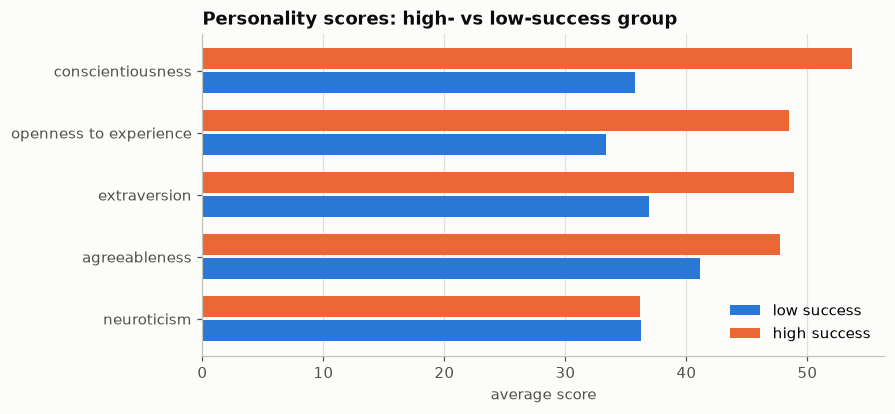

In [31]:
grp2 = sds.groupby('success_high')[trait_cols].mean().T
grp2.columns = ['low success (0)', 'high success (1)']
grp2['difference'] = grp2['high success (1)'] - grp2['low success (0)']
grp2['corr_with_target'] = [sds[c].corr(sds['success_high']) for c in trait_cols]
grp2 = grp2.sort_values('corr_with_target', ascending=False).round(2)
display(grp2)

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(grp2)); h = 0.38
ax.barh(y + h/2, grp2['low success (0)'], h - 0.04, color=BLUE, label='low success')
ax.barh(y - h/2, grp2['high success (1)'], h - 0.04, color=ORANGE, label='high success')
ax.set_yticks(y, [c.replace('_', ' ') for c in grp2.index]); ax.invert_yaxis()
ax.grid(axis='y', visible=False); ax.set_xlabel('average score')
ax.set_title('Personality scores: high- vs low-success group'); ax.legend(loc='lower right')
plt.show()

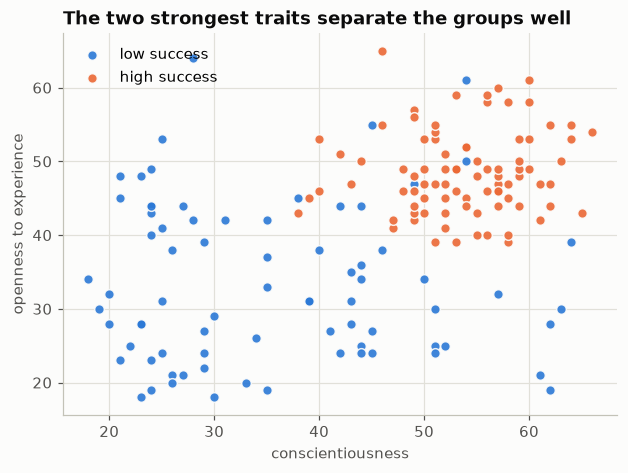

Rule "conscientiousness + openness >= 85 -> high success" is right for 92% of people (baseline 53%)


In [32]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for cls, color, label in [(0, BLUE, 'low success'), (1, ORANGE, 'high success')]:
    s = sds[sds['success_high'] == cls]
    ax.scatter(s['conscientiousness'], s['openness_to_experience'], s=40, color=color,
               edgecolor='#fcfcfb', linewidth=1, alpha=0.9, label=label)
ax.set_xlabel('conscientiousness'); ax.set_ylabel('openness to experience')
ax.set_title('The two strongest traits separate the groups well'); ax.legend(loc='upper left')
plt.show()

sds['top2'] = sds['conscientiousness'] + sds['openness_to_experience']
best2 = max(((t, ((sds['top2'] >= t) == sds['success_high']).mean()) for t in range(40, 140)), key=lambda x: x[1])
print(f'Rule "conscientiousness + openness >= {best2[0]} -> high success" is right for {best2[1]:.0%} of people '
      f'(baseline {sds.success_high.mean():.0%})')

## 6. Cross-dataset check — do the two job files agree on pay?
The Analytics file gives salary *bands*; the DataScience file gives exact figures. For matching titles, compare the Analytics band midpoint with the DataScience median.

In [33]:
rows = []
for t in ['Data Scientist', 'Data Analyst', 'Data Engineer', 'Business Analyst']:
    m = a['job_desig'].str.contains(t, case=False) & ~a['job_desig'].str.contains('senior|sr\\.?|lead|manager', case=False)
    rows.append({'title': t, 'analytics_postings': int(m.sum()),
                 'analytics_avg_band_mid_L': round(a.loc[m, 'salary_mid_L'].mean(), 1),
                 'datascience_median_avg_L': title_stats.loc[t, 'median_avg_L']})
pd.DataFrame(rows).set_index('title')

,analytics_postings,analytics_avg_band_mid_L,datascience_median_avg_L
title,,,
Data Scientist,284,15.0,12.80
Data Analyst,204,8.0,5.00
Data Engineer,76,11.8,10.85
Business Analyst,542,11.4,8.30


## 7. Save cleaned data
The cleaned tables feed `data_analysis.ipynb`. They are plain CSV, so they can also be uploaded to SAS Viya for Learners (VFL).

| File | Changes vs raw |
|---|---|
| `cleaned/analytics_jobs_clean.csv` | duplicates removed, `exp_min/exp_max`, `salary_mid_L`, normalised `cities`/`primary_city`, `role_group`, quality flags |
| `cleaned/ds_jobs_clean.csv` | numeric salaries, outlier flags |
| `cleaned/jds_clean.csv`, `cleaned/sds_clean.csv` | tidy column names, unique `row_key` |

In [34]:
import os
os.makedirs('cleaned', exist_ok=True)
a_out = a.drop(columns=['job_description']).assign(cities=a['cities'].str.join('|'))
a_out['is_data_role'] = a_out['role_group'].isin(['Data Scientist / ML', 'Data / Business Analyst', 'Data Engineer / Big Data'])
a_out.to_csv('cleaned/analytics_jobs_clean.csv', index=False)
d.drop(columns=['avg_salary', 'min_salary', 'max_salary']).to_csv('cleaned/ds_jobs_clean.csv', index=False)
jds.drop(columns=['skill_total']).to_csv('cleaned/jds_clean.csv', index=False)
sds.drop(columns=['top2']).to_csv('cleaned/sds_clean.csv', index=False)
for f in sorted(os.listdir('cleaned')):
    print(f'{f:28s}', pd.read_csv('cleaned/' + f).shape)

analytics_jobs_clean.csv     (14840, 18)
ds_jobs_clean.csv            (1602, 11)
jds_clean.csv                (139, 8)
sds_clean.csv                (161, 8)


## 8. Key insights (summary)

See `README.md` for a full explanation of every output above. The headline points:

1. **Analytics Jobs is broader than "analytics"**. Only 24% of postings are tagged `analytics`. Software, marketing/SEO, finance and data-entry roles are mixed in, so filter by title or skills before analysing data roles.
2. **Experience drives pay** in both job files. In Analytics Jobs, the median minimum experience goes from 1 year in the 0–3 L band to 9 years in the 25–50 L band (r = 0.65). In DataScience Jobs, the median salary rises from 6.4 L at 0 years to 25.6 L at 10 years (r = 0.59).
3. **Bengaluru leads hiring** with 4.1k postings, followed by Mumbai (2.8k) and Gurgaon (2.0k). After the city names are cleaned, **Bengaluru, Mumbai and Delhi NCR pay the most** (12.3–13.0 L), and **Kolkata and Ahmedabad pay the least** (8.5–9.3 L).
4. **Algorithms, product management, software development, data science, C++, R, Spark and ML are the best-paid skills** (about 15.5–17 L). **SEO, SEM, outsourcing and "communication skills" are the lowest-paid** (about 5–8 L).
5. **A "Senior" title adds 57–72% to pay** for every role. Data Architect is the best-paid title at 24 L median, and Data Analyst the lowest at 5 L.
6. **The biggest IT-services hirers pay below the market**. The 8 largest hirers (TCS, Accenture and others) have a median of 9.8 L against 12.0 L for everyone else. Product and finance firms (Adobe, Walmart, PayPal) pay the most.
7. **Skills behind a high salary hike**: dashboard/storytelling and maths/stats matter most, and big-data skill barely matters. A simple total-score rule classifies 87% of people correctly.
8. **Traits behind success**: conscientiousness and openness matter most, and neuroticism shows no relationship. Adding these two scores classifies 92% of people correctly.
9. **Data quality**: we removed 1,001 exact duplicate postings (6%), which had inflated the average salary from 11.8 L to 12.3 L. 1,355 raw location strings were reduced to 467 cities. JDS and SDS contain 2 and 9 *duplicate IDs* that belong to different people, so we added a unique `row_key`.